# 01 — Planning: sourcing the data

## Rough plan

- Does the text of a company's annual report (10-K) predict its share-price volatility over the next 12 months, beyond what last year's volatility already tells us?
- Baseline to beat: last year's volatility 
- FinBERT reads the text (someone else's model) then use our own PyTorch network predicts volatility
- We have two decent sources of data:
1. 10-K Corpus from Kogan. gives item 7 from annual company reports where managers explain how the year went and what worries them, 10,000 approx words per report. Importantly, this dataset also includes the volatility of the equity in question. 1996-2006
2. EDGAR corpus (from Loukas 2021). Gives every 10k report filed from 1993 to 2020 (about 40gb). Note that the above dataset is a subset of this one. Ideally we would like to use this dataset but it requires that we are able to reliably calcuate and match the volatility for each stock via yfianance.

I asked Claude to investigate exactly this problem below:

## Feasibility check: can we make our own volatility labels?

**Why this check.** EDGAR-CORPUS (Loukas et al., 2021) has the text of every 10-K from 1993 to 2020, but **no share prices**,
so nothing to predict. The Kogan et al. (2009) corpus does have volatility labels (calculated from CRSP), but only for 1996–2006.
If we want to use EDGAR-CORPUS on its own, we would have to make the labels ourselves, from free Yahoo Finance prices (`yfinance`).

We test that on one year where we *already know the right answer* (Kogan's 2004 filings), and answer two questions:

1. **Coverage:** for how many of the companies can we get Yahoo prices at all? And are the ones we lose different (riskier)?
2. **Accuracy:** for the ones we can get, does our volatility match Kogan's CRSP volatility?

**The pipeline we are testing** is exactly what an EDGAR-only project would have to do:

```
SEC company number (CIK)  →  ticker (SEC's list)  →  daily prices (Yahoo)  →  volatility over the 12 months after filing
```

In [1]:
import json
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

ROOT = Path("..")                          # this notebook lives in Oscar/, so the repo root is one level up
RAW = ROOT / "data" / "raw"                # downloads, never edited (git-ignored)
PROCESSED = ROOT / "data" / "processed"    # things we make, can be deleted and rebuilt (git-ignored)
RAW.mkdir(parents=True, exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)

YEAR = 2004

### 1. Download Kogan's 2004 labels

We only need two small files: `meta` (filing date, company name, CIK) and `logvol.+12` (Kogan's volatility in the 12 months after filing,
which is the "right answer" we check against). We skip the download if the file is already there.

In [2]:
KOGAN_URL = "https://www.cs.cmu.edu/~ark/10K/data/"
kogan_dir = RAW / "kogan"
kogan_dir.mkdir(exist_ok=True)

for name in [f"{YEAR}.meta.txt", f"{YEAR}.logvol.+12.txt"]:
    target = kogan_dir / name
    if not target.exists():
        urllib.request.urlretrieve(KOGAN_URL + name, target)
        print("downloaded", name)
    else:
        print("already have", name)

already have 2004.meta.txt
already have 2004.logvol.+12.txt


In [3]:
meta = pd.read_csv(kogan_dir / f"{YEAR}.meta.txt", sep="\t", header=None,
                   names=["key", "date", "url", "name", "cik"])
after = pd.read_csv(kogan_dir / f"{YEAR}.logvol.+12.txt", sep=" ", header=None,
                    names=["kogan_logvol", "key"])

df = meta.merge(after, on="key")
print("rows after merge:", len(df))
df = df.drop_duplicates("key")             # the source files repeat some reports (see 01-Data notes)
df["date"] = pd.to_datetime(df["date"].astype(str))
print("reports after removing duplicates:", len(df))
df.head()

rows after merge: 3561
reports after removing duplicates: 3558


,key,date,url,name,cik,kogan_logvol
0,000360206-10-K-2004-03-12,2004-03-12,http://ftp.sec.gov/Archives/edgar/data/824142/...,AAON INC,824142,-3.855595
1,000361105-10-K-2004-07-22,2004-07-22,http://ftp.sec.gov/Archives/edgar/data/1750/00...,AAR CORP,1750,-3.710606
2,00086T103-10-K-2004-03-12,2004-03-12,http://ftp.sec.gov/Archives/edgar/data/1042809...,A C MOORE ARTS & CRAFTS INC,1042809,-3.784096
3,000886309-10-K-2004-01-15,2004-01-15,http://ftp.sec.gov/Archives/edgar/data/61478/0...,ADC TELECOMMUNICATIONS INC,61478,-3.486180
4,00089C107-10-K-2004-07-14,2004-07-14,http://ftp.sec.gov/Archives/edgar/data/884498/...,ADE CORP,884498,-3.405877


### 2. Company number → ticker

Yahoo needs a **ticker** (e.g. `AAPL`), but 10-Ks identify companies by their SEC number (**CIK**). The SEC publishes a CIK → ticker list,
but only for companies listed **today**. That is the first place companies drop out: anything that went bankrupt, was bought, or
de-listed since 2004 is not on it.

(The SEC asks automated downloads to identify themselves, so we send a generic name.)

In [4]:
sec_file = RAW / "sec_company_tickers.json"
if not sec_file.exists():
    req = urllib.request.Request("https://www.sec.gov/files/company_tickers.json",
                                 headers={"User-Agent": "DST-coursework-script research@example.org"})
    sec_file.write_bytes(urllib.request.urlopen(req).read())

sec = pd.DataFrame(json.loads(sec_file.read_text()).values())
sec = sec.drop_duplicates("cik_str")       # some companies have several share classes; keep the first ticker
sec = sec.rename(columns={"cik_str": "cik"})[["cik", "ticker"]]
sec["ticker"] = sec["ticker"].str.replace(".", "-", regex=False)   # Yahoo writes BRK.B as BRK-B

df = df.merge(sec, on="cik", how="left")
print(f"reports whose company has a ticker today: {df['ticker'].notna().sum()} of {len(df)} "
      f"({df['ticker'].notna().mean():.0%})")

reports whose company has a ticker today: 954 of 3558 (27%)


### 3. Download daily prices from Yahoo

One request for all tickers, from the start of 2004 to early 2006 (a filing in December 2004 needs prices up to December 2005).
`auto_adjust=True` corrects prices for splits and dividends, as CRSP does. We save the prices so re-running doesn't download again.
Yahoo prints a warning for every ticker it has no data for; that's expected.

In [5]:
prices_file = PROCESSED / f"yahoo_prices_{YEAR}.pkl"
if prices_file.exists():
    prices = pd.read_pickle(prices_file)
else:
    tickers = sorted(df["ticker"].dropna().unique())
    prices = yf.download(tickers, start=f"{YEAR}-01-01", end=f"{YEAR + 2}-01-31",
                         auto_adjust=True, progress=False, threads=True)["Close"]
    prices.to_pickle(prices_file)

print("price table:", prices.shape[0], "trading days ×", prices.shape[1], "tickers")

price table: 523 trading days × 949 tickers


### 4. Our volatility

Same definition as Kogan et al. (2009): the **standard deviation of daily returns over the 12 months after the filing date**,
then take the **log**. A daily return is the log of today's price over yesterday's.

A full year has about 250 trading days. We require at least 200, so a company that stopped trading part-way isn't counted as usable.

In [6]:
MIN_DAYS = 200

def our_logvol(ticker, filed):
    """Log s.d. of daily log returns in the 12 months after `filed`. Returns (value, number of returns)."""
    if not isinstance(ticker, str) or ticker not in prices.columns:
        return np.nan, 0
    p = prices[ticker]
    window = p[(p.index > filed) & (p.index <= filed + pd.DateOffset(years=1))].dropna()
    returns = np.log(window).diff().dropna()
    if len(returns) < 2:
        return np.nan, len(returns)
    return np.log(returns.std()), len(returns)

df[["our_logvol", "n_days"]] = [our_logvol(t, d) for t, d in zip(df["ticker"], df["date"])]
df["usable"] = df["n_days"] >= MIN_DAYS
df[["name", "ticker", "date", "n_days", "our_logvol", "kogan_logvol"]].head()

,name,ticker,date,n_days,our_logvol,kogan_logvol
0,AAON INC,AAON,2004-03-12,250.0,-3.853087,-3.855595
1,AAR CORP,AIR,2004-07-22,252.0,-3.681246,-3.710606
2,A C MOORE ARTS & CRAFTS INC,NaN,2004-03-12,0.0,NaN,-3.784096
3,ADC TELECOMMUNICATIONS INC,NaN,2004-01-15,0.0,NaN,-3.486180
4,ADE CORP,NaN,2004-07-14,0.0,NaN,-3.405877


### 5. Question 1: coverage

How many reports survive each step? And is the group we keep **different** from the group we lose?
If Yahoo mostly loses companies that later failed, the ones we keep should be *less* volatile.

In [7]:
funnel = pd.Series({
    "Kogan 2004 reports": len(df),
    "company has a ticker today": df["ticker"].notna().sum(),
    "Yahoo has any prices": df["ticker"].isin(prices.columns[prices.notna().any()]).sum(),
    f"≥{MIN_DAYS} trading days after filing (usable)": df["usable"].sum(),
})
pd.DataFrame({"reports": funnel, "share": (funnel / len(df)).map("{:.0%}".format)})

,reports,share
Kogan 2004 reports,3558,100%
company has a ticker today,954,27%
Yahoo has any prices,919,26%
≥200 trading days after filing (usable),917,26%


Kogan's log volatility, companies we KEEP: mean -3.86
Kogan's log volatility, companies we LOSE: mean -3.65
=> the companies we lose are about 23% more volatile on average


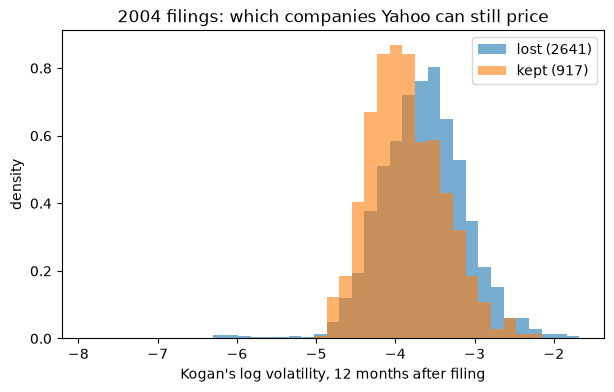

In [8]:
kept, lost = df[df["usable"]], df[~df["usable"]]
print(f"Kogan's log volatility, companies we KEEP: mean {kept['kogan_logvol'].mean():.2f}")
print(f"Kogan's log volatility, companies we LOSE: mean {lost['kogan_logvol'].mean():.2f}")
print(f"=> the companies we lose are about {np.exp(lost['kogan_logvol'].mean() - kept['kogan_logvol'].mean()) - 1:.0%} "
      "more volatile on average")

fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(df["kogan_logvol"].min(), df["kogan_logvol"].max(), 40)
ax.hist(lost["kogan_logvol"], bins=bins, alpha=0.6, density=True, label=f"lost ({len(lost)})")
ax.hist(kept["kogan_logvol"], bins=bins, alpha=0.6, density=True, label=f"kept ({len(kept)})")
ax.set_xlabel("Kogan's log volatility, 12 months after filing")
ax.set_ylabel("density")
ax.set_title(f"{YEAR} filings: which companies Yahoo can still price")
ax.legend()
plt.show()

### 6. Question 2: accuracy

For the usable companies we have two numbers for the same thing: ours (Yahoo) and Kogan's (CRSP). If our method is right, they
should sit on the diagonal line. A difference of 0.1 in log volatility is about 10% in volatility.

usable reports compared:          917
correlation:                      0.988
average difference (ours − Kogan): -0.009
median absolute difference:       0.026
within 0.1 of Kogan (~10%):        91%


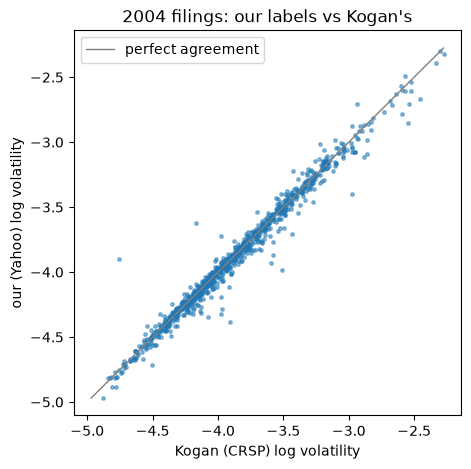

In [9]:
diff = kept["our_logvol"] - kept["kogan_logvol"]
print(f"usable reports compared:          {len(kept)}")
print(f"correlation:                      {np.corrcoef(kept['our_logvol'], kept['kogan_logvol'])[0, 1]:.3f}")
print(f"average difference (ours − Kogan): {diff.mean():+.3f}")
print(f"median absolute difference:       {diff.abs().median():.3f}")
print(f"within 0.1 of Kogan (~10%):        {(diff.abs() < 0.1).mean():.0%}")

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(kept["kogan_logvol"], kept["our_logvol"], s=6, alpha=0.5)
lims = [kept[["kogan_logvol", "our_logvol"]].min().min(), kept[["kogan_logvol", "our_logvol"]].max().max()]
ax.plot(lims, lims, color="grey", lw=1, label="perfect agreement")
ax.set_xlabel("Kogan (CRSP) log volatility")
ax.set_ylabel("our (Yahoo) log volatility")
ax.set_title(f"{YEAR} filings: our labels vs Kogan's")
ax.legend()
plt.show()

The biggest disagreements are worth looking at: they usually show **the CIK now belongs to a different company**
(e.g. after a merger), so we priced the wrong shares.

In [10]:
kept.assign(diff=diff).loc[diff.abs().sort_values(ascending=False).index,
    ["name", "ticker", "date", "our_logvol", "kogan_logvol", "diff"]].head(8)

,name,ticker,date,our_logvol,kogan_logvol,diff
1134,FEDERAL AGRICULTURAL MORTGAGE CORP,AGM,2004-03-15,-3.903101,-4.755551,0.852451
2792,SCHERING PLOUGH CORP,MRK,2004-02-26,-3.624998,-4.169959,0.544961
1364,HON INDUSTRIES INC,HNI,2004-03-01,-4.387775,-3.906901,-0.480874
632,ROTO-ROOTER INC,CHE,2004-03-12,-3.986060,-3.510844,-0.475217
282,ARTS WAY MANUFACTURING CO INC,ARTW,2004-03-01,-3.400133,-2.976659,-0.423473
778,CORN PRODUCTS INTERNATIONAL INC,INGR,2004-03-12,-4.325038,-3.979991,-0.345047
2003,MERCURY COMPUTER SYSTEMS INC,MRCY,2004-09-10,-3.928625,-3.596935,-0.331690
3403,WATERS CORP /DE/,WAT,2004-03-12,-4.283536,-3.966421,-0.317115


### 7. Conclusion (2004 filings, run 11 Nov 2026)

**Question 2, accuracy: yes.** Where we can get prices, our method reproduces Kogan's CRSP labels closely: correlation 0.99,
median difference 0.026 in log volatility (about 2.6%), 91% within 0.1. The calculation itself is not the problem. The few big
misses are mostly mapping errors, e.g. Schering-Plough's CIK now points to Merck's ticker (MRK) after their 2009 merger.

**Question 1, coverage: no.** Only **26%** of 2004 filings can be labelled (917 of 3,558). Almost all the loss is at the first
step: the SEC's list only has tickers for companies listed *today*. And the loss is **not random**: the companies we lose were about
**23% more volatile** than those we keep. That is survivorship bias, and it falls on the very thing we are trying to predict.

**What this means for the project.**
- An EDGAR-only project with Yahoo labels would throw away about three quarters of the 1996–2006 reports and keep the safer companies.
  For later years coverage is better but still poor (44% for 2018 in the feasibility check).
- Better: **labels from Kogan (CRSP), text from EDGAR-CORPUS**, matched by CIK + year. Yahoo is then only needed for the optional
  modern check, where we report its bias using the numbers above.
- If the library gives us CRSP via WRDS, both problems go away.

**Limits of this check:** one year only; one CIK → ticker route (reading the ticker from the filing's own text, as in the 2018
check, may recover some more companies).

## Back to my work:

It looks like the edgar dataset is not sufficient on its own. Thus we resort to only using the companies and years we have available within the kogan dataset (as this comes with the volatility data) and then merge in the full 10-k for those instances from the edgar dataset. This leads to a few things we to get right:
1. Matching the data - both datasets have the company number (CIK) and the year of publification, this is what we will use to merge the two datasets.
2. A way to confirm the matches actually worked. Keeping kogan's item 7 will allow us to reconcile it with the extracted item 7 report from edgar. 
3. Keeping item 7 from kogan will also allow us to reproduce the results from the paper.

We start by measuring how much data is conserved after the merge.

## Possible extra data sources (if we want more later)

Not needed for the core study (Kogan labels + EDGAR-CORPUS text). Only useful for filings after 2006, e.g. to get Risk Factors (Item 1A).

- **NCCU extended 10-K corpus** (Tsai & Wang, clip.csie.org/10K): Kogan's setup extended to 1996–2013 with volatility labels. Best option. Site's security certificate has expired, so email the authors.
- **WRDS / CRSP** (same price source as Kogan, includes dead companies): Bristol subscribes, but the library guide says it's for Business and Economics masters students. Ask the library / Dan Lawson.
- **Bloomberg, LSEG Workspace (Datastream), S&P Capital IQ Pro**: keep prices for dead companies, but licensed (can't go in a public repo) and slow to bulk-download. Best for a small check, e.g. price ~100 of the companies Yahoo lost above to measure the bias.
- **Earnings-call datasets** (EC, Qin & Yang 2019; MAEC, Li et al. 2020): public text with volatility labels, 2015–18, but small, a different kind of text, and a 2024 paper found most volatility windows misaligned. Cite, don't use.
- **Yahoo Finance**: free, any year, but 26% coverage for 2004 and the lost companies are ~23% more volatile (above). Last resort, with the bias reported.